In [6]:
!pip install catboost lightgbm xgboost -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import KFold
from sklearn.metrics import r2_score
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostRegressor

SEED = 1234
np.random.seed(SEED)
N_SPLITS = 2

print('All libraries imported')


[notice] A new release of pip is available: 26.0.1 -> 26.1.1
[notice] To update, run: pip install --upgrade pip
All libraries imported


In [7]:
PATH = 'dataset/'
train = pd.read_csv(PATH + 'train.csv')
test  = pd.read_csv(PATH + 'test.csv')
sample_sub = pd.read_csv(PATH + 'sample_submission.csv')

print(f'Train : {train.shape}  ,  Test : {test.shape}')
print(f'Train days: {sorted(train["day"].unique())}  ,  Test days: {sorted(test["day"].unique())}')
train.head(3)

Train : (77299, 11)  ,  Test : (41778, 10)
Train days: [np.int64(48), np.int64(49)]  ,  Test days: [np.int64(49)]


,Index,geohash,day,timestamp,demand,RoadType,NumberofLanes,LargeVehicles,Landmarks,Temperature,Weather
0,0,qp02z1,48,0:0,0.048804,NaN,1,Not Allowed,No,NaN,NaN
1,1,qp02zt,48,0:0,0.118507,Residential,3,Allowed,Yes,31.104565,Sunny
2,2,qp08bj,48,0:0,0.027132,Residential,1,Not Allowed,No,25.919267,Sunny


In [8]:
def engineer_features(df, train_ref=None):

    df = df.copy()
    ref = train_ref if train_ref is not None else df
    global_mean = ref['demand'].mean()

    # 1. parse timestamp

    df['hour']   = df['timestamp'].str.split(':').str[0].astype(int)
    df['minute'] = df['timestamp'].str.split(':').str[1].astype(int)
    df['time_in_minutes'] = df['hour'] * 60 + df['minute']

    # 2. cyclic encoding

    df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
    df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)
    df['min_sin']  = np.sin(2 * np.pi * df['minute'] / 60)
    df['min_cos']  = np.cos(2 * np.pi * df['minute'] / 60)

    # 3. time-of-day flags
    df['is_peak_hour'] = ((df['hour'].between(7, 9)) | (df['hour'].between(17, 19))).astype(int)
    df['is_night']     = ((df['hour'] >= 22) | (df['hour'] <= 5)).astype(int)
    df['is_morning']   = df['hour'].between(6, 11).astype(int)
    df['is_afternoon'] = df['hour'].between(12, 17).astype(int)

    # 4. geohash target encoding — full train ref

    geo_stats = ref.groupby('geohash')['demand'].agg(
        geo_mean='mean', geo_median='median', geo_std='std', geo_max='max'
    ).reset_index()
    df = df.merge(geo_stats, on='geohash', how='left')
    for c in ['geo_mean', 'geo_median', 'geo_std', 'geo_max']:
        df[c] = df[c].fillna(global_mean)

    # 5. broader region stats (geohash prefix = larger geographic area)
    df['geo4'] = df['geohash'].str[:4]
    geo4_ref = ref.copy()
    geo4_ref['geo4'] = geo4_ref['geohash'].str[:4]
    geo4_mean = geo4_ref.groupby('geo4')['demand'].mean().reset_index()
    geo4_mean.columns = ['geo4', 'geo4_mean']
    df = df.merge(geo4_mean, on='geo4', how='left')
    df['geo4_mean'] = df['geo4_mean'].fillna(global_mean)

    # 6. location x hour interaction

    hour_geo = ref.copy()
    hour_geo['hour'] = hour_geo['timestamp'].str.split(':').str[0].astype(int)
    hg_mean = hour_geo.groupby(['geohash', 'hour'])['demand'].mean().reset_index()
    hg_mean.columns = ['geohash', 'hour', 'geo_hour_mean']
    df = df.merge(hg_mean, on=['geohash', 'hour'], how='left')
    df['geo_hour_mean'] = df['geo_hour_mean'].fillna(global_mean)


    geo_range = ref.groupby('geohash')['demand'].apply(
        lambda x: x.quantile(0.75) - x.quantile(0.25)
    ).reset_index()
    geo_range.columns = ['geohash', 'geo_iqr']
    df = df.merge(geo_range, on='geohash', how='left')
    df['geo_iqr'] = df['geo_iqr'].fillna(global_mean)

    df['geo_vs_region'] = df['geo_mean'] - df['geo4_mean']

    geo_min = ref.copy()
    geo_min['minute'] = geo_min['timestamp'].str.split(':').str[1].astype(int)
    gm_mean = geo_min.groupby(['geohash', 'minute'])['demand'].mean().reset_index()
    gm_mean.columns = ['geohash', 'minute', 'geo_min_mean']
    df = df.merge(gm_mean, on=['geohash', 'minute'], how='left')
    df['geo_min_mean'] = df['geo_min_mean'].fillna(df['geo_hour_mean'])

    # 8. binary categoricals
    df['large_vehicles_flag'] = (df['LargeVehicles'] == 'Allowed').astype(int)
    df['landmarks_flag']      = (df['Landmarks'] == 'Yes').astype(int)

    # 9. one-hot encode RoadType and Weather

    df['RoadType_filled'] = df['RoadType'].fillna('Unknown')
    df['Weather_filled']  = df['Weather'].fillna('Unknown')
    road_dummies    = pd.get_dummies(df['RoadType_filled'], prefix='road')
    weather_dummies = pd.get_dummies(df['Weather_filled'],  prefix='weather')
    df = pd.concat([df, road_dummies, weather_dummies], axis=1)

    # 10. temperature
    df['temp_missing'] = df['Temperature'].isnull().astype(int)
    df['Temperature']  = df['Temperature'].fillna(ref['Temperature'].median())
    df['temp_bin'] = pd.cut(
        df['Temperature'],
        bins=[-np.inf, 0, 10, 20, 30, np.inf],
        labels=[0, 1, 2, 3, 4]
    ).astype(int)

    # 11. interaction features
    df['lane_capacity']   = df['NumberofLanes'] * (1 + df['large_vehicles_flag'])
    df['peak_x_lanes']    = df['is_peak_hour'] * df['NumberofLanes']
    df['night_x_highway'] = df['is_night'] * (df['road_Highway'] if 'road_Highway' in df.columns else 0)

    # 12. drop raw / intermediate columns
    drop_cols = [
        'timestamp', 'geohash', 'geo4',
        'RoadType', 'LargeVehicles', 'Landmarks', 'Weather',
        'RoadType_filled', 'Weather_filled'
    ]
    df = df.drop(columns=[c for c in drop_cols if c in df.columns])

    return df


train_fe = engineer_features(train, train_ref=train)
test_fe  = engineer_features(test,  train_ref=train)

TARGET = 'demand'
feature_cols = [c for c in train_fe.columns if c not in [TARGET, 'Index']]

for col in feature_cols:
    if col not in test_fe.columns:
        test_fe[col] = 0
        print(f'added missing column to test: {col}')

X      = train_fe[feature_cols].values
y      = train_fe[TARGET].values
X_test = test_fe[feature_cols].values

print(f'train_fe shape : {train_fe.shape}')
print(f'test_fe shape  : {test_fe.shape}')
print(f'total features : {len(feature_cols)}')
print(f'null check train: {pd.DataFrame(X, columns=feature_cols).isnull().sum().sum()}')
print(f'null check test : {pd.DataFrame(X_test, columns=feature_cols).isnull().sum().sum()}')

train_fe shape : (77299, 41)
test_fe shape  : (41778, 40)
total features : 39
null check train: 0
null check test : 0


In [9]:
from sklearn.model_selection import GroupKFold

kf = GroupKFold(n_splits=N_SPLITS)
groups = train['day'].values


In [10]:
# LightGBM

N_MODELS = 3
oof_preds = np.zeros((len(y), N_MODELS))
test_preds = np.zeros((len(X_test), N_MODELS))
scores = {'LightGBM': [], 'XGBoost': [], 'CatBoost': []}

lgb_params = {
    'objective':         'regression',
    'metric':            'rmse',
    'n_estimators':      2000,
    'learning_rate':     0.03,
    'num_leaves':        127,
    'min_child_samples': 20,
    'subsample':         0.8,
    'subsample_freq':    1,
    'colsample_bytree':  0.8,
    'reg_alpha':         0.1,
    'reg_lambda':        0.2,
    'random_state':      SEED,
    'n_jobs':            -1,
    'verbose':           -1,
}

print('Training LightGBM')
for fold, (tr_idx, va_idx) in enumerate(kf.split(X, y, groups=groups), 1):
    model = lgb.LGBMRegressor(**lgb_params)
    model.fit(
        X[tr_idx], y[tr_idx],
        eval_set=[(X[va_idx], y[va_idx])],
        callbacks=[lgb.early_stopping(100, verbose=False),
                   lgb.log_evaluation(500)]
    )
    val_pred = model.predict(X[va_idx])
    oof_preds[va_idx, 0] = val_pred
    test_preds[:, 0]    += model.predict(X_test) / N_SPLITS

    s = max(0, r2_score(y[va_idx], val_pred)) * 100
    scores['LightGBM'].append(s)
    print(f'  Fold {fold} , iters={model.best_iteration_:4d} , Score={s:.4f}')

lgb_oof_score = max(0, r2_score(y, oof_preds[:, 0])) * 100
print(f'  LightGBM OOF Score: {lgb_oof_score:.4f}')

Training LightGBM
  Fold 1 , iters= 106 , Score=90.7189
  Fold 2 , iters= 150 , Score=78.8451
  LightGBM OOF Score: 89.4719


In [11]:
# XGBoost


xgb_params = {
    'n_estimators':          2000,
    'learning_rate':         0.03,
    'max_depth':             7,
    'min_child_weight':      5,
    'subsample':             0.8,
    'colsample_bytree':      0.8,
    'colsample_bylevel':     0.8,
    'gamma':                 0.1,
    'reg_alpha':             0.1,
    'reg_lambda':            1.0,
    'tree_method':           'hist',
    'random_state':          SEED,
    'n_jobs':                -1,
    'verbosity':             0,
    'eval_metric':           'rmse',
    'early_stopping_rounds': 100,
}

print('Training XGBoost')
for fold, (tr_idx, va_idx) in enumerate(kf.split(X, y, groups=groups), 1):
    model = xgb.XGBRegressor(**xgb_params)
    model.fit(
        X[tr_idx], y[tr_idx],
        eval_set=[(X[va_idx], y[va_idx])],
        verbose=False,
    )
    val_pred = model.predict(X[va_idx])
    oof_preds[va_idx, 1] = val_pred
    test_preds[:, 1]    += model.predict(X_test) / N_SPLITS

    s = max(0, r2_score(y[va_idx], val_pred)) * 100
    scores['XGBoost'].append(s)
    print(f'  Fold {fold} , iters={model.best_iteration:4d} , Score={s:.4f}')

xgb_oof_score = max(0, r2_score(y, oof_preds[:, 1])) * 100
print(f'  XGBoost OOF Score: {xgb_oof_score:.4f}')

Training XGBoost
  Fold 1 , iters= 148 , Score=91.1434
  Fold 2 , iters= 161 , Score=81.8839
  XGBoost OOF Score: 90.1721


In [12]:
# CatBoost
# uses symmetric (oblivious) trees and ordered boosting
# architecturally most different from the other two — gives the highest
# diversity benefit in the ensemble

cat_params = {
    'iterations':          2000,
    'learning_rate':       0.03,
    'depth':               7,
    'l2_leaf_reg':         3.0,
    'min_data_in_leaf':    20,
    'subsample':           0.8,
    'colsample_bylevel':   0.8,
    'random_seed':         SEED,
    'od_type':             'Iter',
    'od_wait':             100,
    'verbose':             False,
    'allow_writing_files': False,
}

print('Training CatBoost')
for fold, (tr_idx, va_idx) in enumerate(kf.split(X, y, groups=groups), 1):
    model = CatBoostRegressor(**cat_params)
    model.fit(
        X[tr_idx], y[tr_idx],
        eval_set=(X[va_idx], y[va_idx]),
        use_best_model=True,
    )
    val_pred = model.predict(X[va_idx])
    oof_preds[va_idx, 2] = val_pred
    test_preds[:, 2]    += model.predict(X_test) / N_SPLITS

    s = max(0, r2_score(y[va_idx], val_pred)) * 100
    scores['CatBoost'].append(s)
    print(f'  Fold {fold} , iters={model.best_iteration_:4d} , Score={s:.4f}')

cat_oof_score = max(0, r2_score(y, oof_preds[:, 2])) * 100
print(f'  CatBoost OOF Score: {cat_oof_score:.4f}')

Training CatBoost
  Fold 1 , iters= 201 , Score=91.1358
  Fold 2 , iters= 108 , Score=80.2290
  CatBoost OOF Score: 89.9905


BASE MODEL SUMMARY
  LightGBM     OOF Score: 89.4719
  XGBoost      OOF Score: 90.1721
  CatBoost     OOF Score: 89.9905
  Simple avg   OOF Score: 90.0854

Correlation between OOF predictions:
          LightGBM  XGBoost  CatBoost
LightGBM    1.0000   0.9972    0.9963
XGBoost     0.9972   1.0000    0.9970
CatBoost    0.9963   0.9970    1.0000


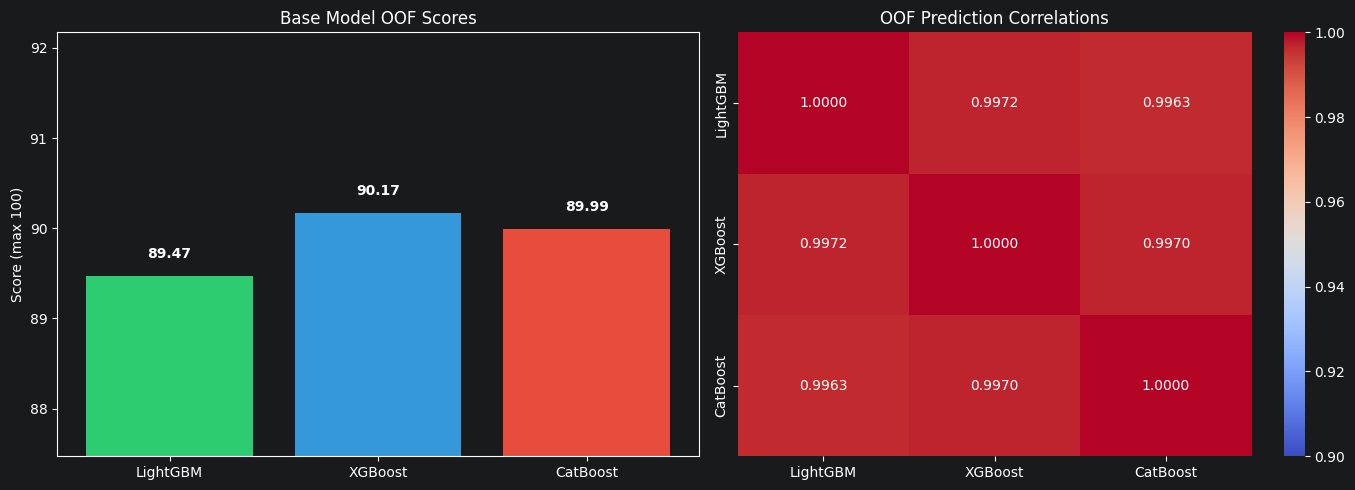

In [13]:

print('BASE MODEL SUMMARY')

model_names = ['LightGBM', 'XGBoost', 'CatBoost']
oof_scores  = [lgb_oof_score, xgb_oof_score, cat_oof_score]
for name, sc in zip(model_names, oof_scores):
    print(f'  {name:<12} OOF Score: {sc:.4f}')
print(f'  Simple avg   OOF Score: {max(0, r2_score(y, oof_preds.mean(axis=1)) * 100):.4f}')

oof_df = pd.DataFrame(oof_preds, columns=['LightGBM', 'XGBoost', 'CatBoost'])
print('\nCorrelation between OOF predictions:')
print(oof_df.corr().round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(model_names, oof_scores, color=['#2ecc71', '#3498db', '#e74c3c'])
axes[0].set_ylabel('Score (max 100)')
axes[0].set_title('Base Model OOF Scores')
axes[0].set_ylim(min(oof_scores) - 2, min(max(oof_scores) + 2, 100))
for i, v in enumerate(oof_scores):
    axes[0].text(i, v + 0.2, f'{v:.2f}', ha='center', fontweight='bold')

sns.heatmap(oof_df.corr(), annot=True, fmt='.4f', cmap='coolwarm',
            vmin=0.9, vmax=1.0, ax=axes[1])
axes[1].set_title('OOF Prediction Correlations')

plt.tight_layout()
plt.show()

In [14]:

scaler = StandardScaler()
meta_X_train = scaler.fit_transform(oof_preds)
meta_X_test  = scaler.transform(test_preds)

print('Tuning Ridge alpha...')
best_alpha, best_score = None, -np.inf
for alpha in [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0]:
    ridge = Ridge(alpha=alpha)
    ridge.fit(meta_X_train, y)
    preds = ridge.predict(meta_X_train)
    sc = max(0, r2_score(y, preds)) * 100
    print(f'  alpha={alpha:<8} , score: {sc:.4f}')
    if sc > best_score:
        best_score = sc
        best_alpha = alpha

print(f'\nBest alpha: {best_alpha}')

meta_model = Ridge(alpha=best_alpha)
meta_model.fit(meta_X_train, y)

print('\nMeta-learner weights:')
for name, coef in zip(model_names, meta_model.coef_):
    print(f'  {name:<12}: {coef:.4f}')
print(f'  Intercept   : {meta_model.intercept_:.4f}')

Tuning Ridge alpha...
  alpha=0.0001   , score: 90.8932
  alpha=0.001    , score: 90.8932
  alpha=0.01     , score: 90.8932
  alpha=0.1      , score: 90.8932
  alpha=1.0      , score: 90.8931
  alpha=10.0     , score: 90.8924

Best alpha: 0.0001

Meta-learner weights:
  LightGBM    : -0.0653
  XGBoost     : 0.1677
  CatBoost    : 0.0330
  Intercept   : 0.0939


FINAL SCORES COMPARISON
  LightGBM    : 89.4719
  XGBoost     : 90.1721
  CatBoost    : 89.9905
  Simple avg  : 90.0854
  Stacked     : 90.8932


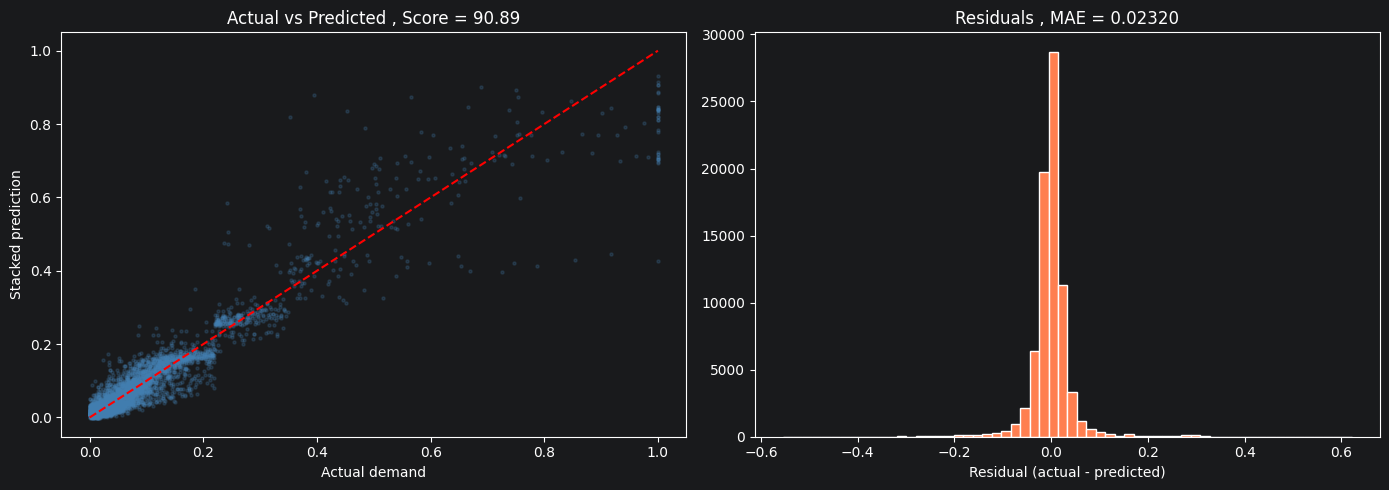

In [15]:
stacked_oof = meta_model.predict(meta_X_train)
stacked_oof_score = max(0, r2_score(y, stacked_oof)) * 100

print('FINAL SCORES COMPARISON')

for name, sc in zip(model_names, oof_scores):
    print(f'  {name:<12}: {sc:.4f}')
print(f'  Simple avg  : {max(0, r2_score(y, oof_preds.mean(axis=1)) * 100):.4f}')
print(f'  Stacked     : {stacked_oof_score:.4f}')

sample_idx = np.random.choice(len(y), size=5000, replace=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y[sample_idx], stacked_oof[sample_idx],
                alpha=0.2, s=5, color='steelblue')
axes[0].plot([0, 1], [0, 1], 'r--', lw=1.5)
axes[0].set_xlabel('Actual demand')
axes[0].set_ylabel('Stacked prediction')
axes[0].set_title(f'Actual vs Predicted , Score = {stacked_oof_score:.2f}')

residuals = y - stacked_oof
axes[1].hist(residuals, bins=60, color='coral', edgecolor='white')
axes[1].set_xlabel('Residual (actual - predicted)')
axes[1].set_title(f'Residuals , MAE = {np.mean(np.abs(residuals)):.5f}')

plt.tight_layout()
plt.show()

Distribution check — predicted vs actual:
                        train actual  test predicted
mean                         0.09394         0.11111
median                       0.04776         0.05819
std                          0.14219         0.15396
p10                          0.00642         0.00575
p90                          0.21646         0.28851

predicted/actual mean ratio: 1.183
Distribution looks reasonable — safe to submit


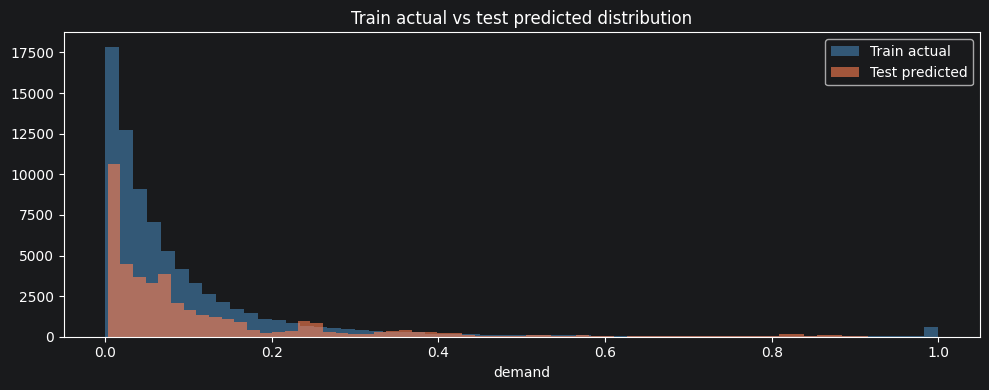

In [16]:
final_preds = meta_model.predict(meta_X_test)
final_preds = np.clip(final_preds, 0, 1)

print('Distribution check — predicted vs actual:')
print(f"{'':20} {'train actual':>15} {'test predicted':>15}")
print(f"{'mean':20} {y.mean():>15.5f} {final_preds.mean():>15.5f}")
print(f"{'median':20} {np.median(y):>15.5f} {np.median(final_preds):>15.5f}")
print(f"{'std':20} {y.std():>15.5f} {final_preds.std():>15.5f}")
print(f"{'p10':20} {np.percentile(y, 10):>15.5f} {np.percentile(final_preds, 10):>15.5f}")
print(f"{'p90':20} {np.percentile(y, 90):>15.5f} {np.percentile(final_preds, 90):>15.5f}")


ratio = final_preds.mean() / y.mean()
print(f'\npredicted/actual mean ratio: {ratio:.3f}')
if ratio > 1.5 or ratio < 0.7:
    print('WARNING: large distribution mismatch — check features before submitting')
else:
    print('Distribution looks reasonable — safe to submit')

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(y, bins=60, alpha=0.6, label='Train actual', color='steelblue', edgecolor='none')
ax.hist(final_preds, bins=60, alpha=0.6, label='Test predicted', color='coral', edgecolor='none')
ax.set_title('Train actual vs test predicted distribution')
ax.set_xlabel('demand')
ax.legend()
plt.tight_layout()
plt.show()

In [17]:
submission = pd.DataFrame({
    'Index':  test['Index'],
    'demand': final_preds
})

assert len(submission) == 41778,                         f'Expected 41778 rows, got {len(submission)}'
assert list(submission.columns) == ['Index', 'demand'],  'Column name mismatch'
assert submission['demand'].isnull().sum() == 0,          'NaN in predictions'
assert (submission['demand'] >= 0).all(),                 'Negative predictions found'
assert (submission['demand'] <= 1).all(),                 'Predictions above 1 found'

submission.to_csv('submission_stacked14.csv', index=False)

print('Submission saved: submission_stacked14.csv')
print(f'Shape      : {submission.shape}')
print(f'Pred range : [{final_preds.min():.5f}, {final_preds.max():.5f}]')
print(f'Pred mean  : {final_preds.mean():.5f}')
submission.head(10)

Submission saved: submission_stacked14.csv
Shape      : (41778, 2)
Pred range : [0.00279, 0.91513]
Pred mean  : 0.11111


,Index,demand
0,0,0.059476
1,1,0.010593
2,2,0.070787
3,3,0.057478
4,4,0.054060
5,5,0.067413
6,6,0.032167
7,7,0.161630
8,8,0.026030
9,9,0.080925


In [18]:
try:
    from google.colab import files
    files.download('submission_stacked.csv')
except ImportError:
    print('submission_stacked.csv saved to disk.')

submission_stacked.csv saved to disk.


## Step 8 — Analysis plots

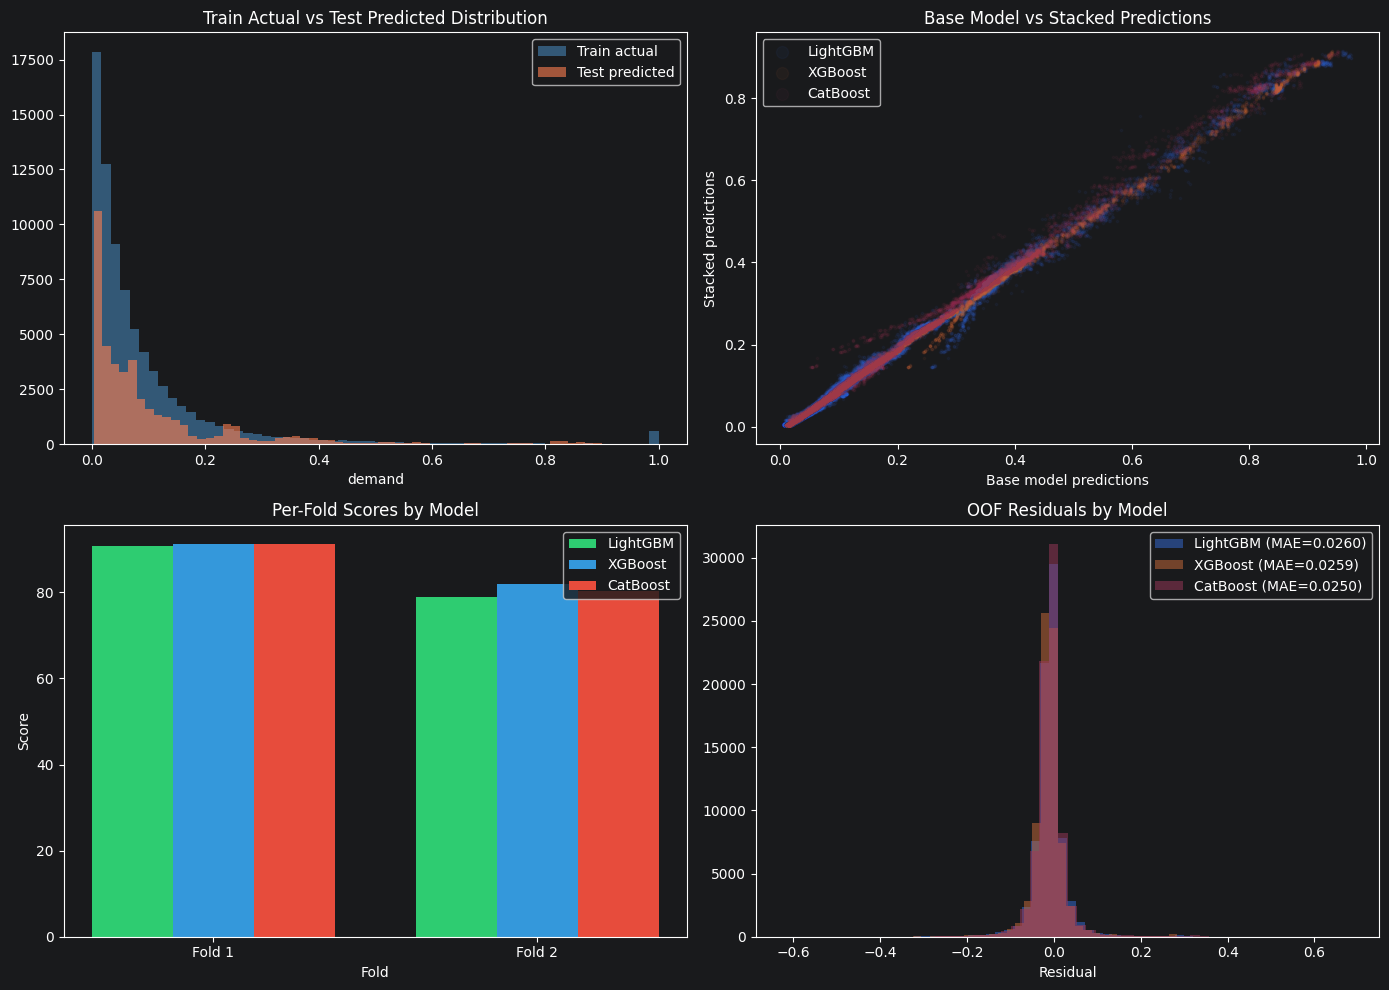

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].hist(y, bins=60, alpha=0.6, label='Train actual', color='steelblue', edgecolor='none')
axes[0, 0].hist(final_preds, bins=60, alpha=0.6, label='Test predicted', color='coral', edgecolor='none')
axes[0, 0].set_title('Train Actual vs Test Predicted Distribution')
axes[0, 0].set_xlabel('demand')
axes[0, 0].legend()

for i, name in enumerate(model_names):
    axes[0, 1].scatter(test_preds[:, i], final_preds, alpha=0.05, s=3, label=name)
axes[0, 1].set_xlabel('Base model predictions')
axes[0, 1].set_ylabel('Stacked predictions')
axes[0, 1].set_title('Base Model vs Stacked Predictions')
axes[0, 1].legend(markerscale=5)

x_pos = np.arange(N_SPLITS)
w = 0.25
colors = ['#2ecc71', '#3498db', '#e74c3c']
for i, (name, sc_list) in enumerate(scores.items()):
    axes[1, 0].bar(x_pos + i * w, sc_list, w, label=name, color=colors[i])
axes[1, 0].set_xlabel('Fold')
axes[1, 0].set_ylabel('Score')
axes[1, 0].set_title('Per-Fold Scores by Model')
axes[1, 0].set_xticks(x_pos + w)
axes[1, 0].set_xticklabels([f'Fold {i+1}' for i in range(N_SPLITS)])
axes[1, 0].legend()

for i, name in enumerate(model_names):
    r = y - oof_preds[:, i]
    axes[1, 1].hist(r, bins=60, alpha=0.5,
                    label=f'{name} (MAE={np.mean(np.abs(r)):.4f})',
                    edgecolor='none')
axes[1, 1].set_xlabel('Residual')
axes[1, 1].set_title('OOF Residuals by Model')
axes[1, 1].legend()

plt.tight_layout()
plt.show()